# Disneyland reviews: complaint patterns across branches
### BDCC Lab 1

Guest reviews combine descriptions of attractions with comments about queues, prices and service, so a park's overall rating may conceal specific difficulties during a visit. This analysis examines those difficulties by preparing the review data, representing its vocabulary with bag-of-words and TF-IDF, and grouping explicitly mentioned complaints into review-level baskets. We then use Apriori and association rules to compare recurring combinations across branches, while keeping their counts and denominators visible.

The analysis reconciles the group's **BDCC LAB 1.ipynb** draft with the earlier review-analysis workbook. It retains the draft's 5,000-term TF-IDF representation, first-review inspection and sparsity calculation, while removing the repeated vectorizer fit and adding the checks needed for branch comparisons. The set-based transactions, absolute-support convention, Apriori function and single-consequent rules follow the supplied class FIM notebook. The attraction results remain descriptive, and the recommendations concern issues to investigate rather than a validated attraction recommender.

**Reproduction.** Run the notebook from top to bottom. The hosted CSV path is used when available, and an explicitly reported local fallback supports execution beside the CSV. The source data and the two input notebooks are not modified. Section 8 is an optional extension, while the other sections form the main analysis. Interpretations are calculated from the current run rather than copied from earlier outputs.

## 1. Data loading
We load the six supplied columns and preserve review identifiers as strings. The hosted path and Latin-1 encoding follow the group draft, while a file digest and package versions record exactly which input and environment produced the results.

In [1]:
# Run once if the notebook environment does not have these packages.
# %pip install pandas numpy matplotlib scikit-learn vaderSentiment


In [2]:
import hashlib
import html
import importlib.metadata
import json
import platform
import re
from itertools import combinations
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfTransformer,
    TfidfVectorizer,
)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

SEED = 42
DATA_PATH = Path("/mnt/data/public/disneyland-reviews/DisneylandReviews.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("DisneylandReviews.csv")
    print("Hosted file unavailable; checking the local CSV.")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place the CSV beside this notebook or edit DATA_PATH."
    )

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
raw = pd.read_csv(DATA_PATH, encoding="latin-1", dtype={"Review_ID": "string"})
required = [
    "Review_ID",
    "Rating",
    "Year_Month",
    "Reviewer_Location",
    "Review_Text",
    "Branch",
]
if not set(required).issubset(raw.columns):
    raise ValueError("The input does not contain all six expected columns.")
input_digest = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Input:", DATA_PATH.resolve())
print("Shape:", raw.shape)
display(raw.head(3))
display(raw.dtypes.rename("data_type").to_frame())


Hosted file unavailable; checking the local CSV.


Input: C:\Users\jlgel\Downloads\BDCC-Lab1-\DisneylandReviews.csv
Shape: (42656, 6)


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the ...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomo...",Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise it would be...,Disneyland_HongKong


,data_type
Review_ID,string
Rating,int64
Year_Month,str
Reviewer_Location,str
Review_Text,str
Branch,str


In [3]:
display(Markdown(f"""### Findings and interpretation

The file contains **{len(raw):,} review records and {raw.shape[1]}
columns**, and its identifiers, ratings, dates, locations and text
provide the information needed for branch-level analysis. However,
`Review_ID` identifies a review rather than a person, so we count review
records and do not interpret repeated mentions as independent visitors.
`Reviewer_Location` describes a stated origin, whereas `Branch`
identifies the reviewed park, and the distinction is maintained
throughout the analysis. Latin-1 follows the group draft, although
successful decoding does not establish that all punctuation was
originally encoded correctly."""))


### Findings and interpretation

The file contains **42,656 review records and 6
columns**, and its identifiers, ratings, dates, locations and text
provide the information needed for branch-level analysis. However,
`Review_ID` identifies a review rather than a person, so we count review
records and do not interpret repeated mentions as independent visitors.
`Reviewer_Location` describes a stated origin, whereas `Branch`
identifies the reviewed park, and the distinction is maintained
throughout the analysis. Latin-1 follows the group draft, although
successful decoding does not establish that all punctuation was
originally encoded correctly.

## 2. Cleaning and data-quality checks
We distinguish null values from placeholders, remove only exact duplicate rows, and retain conflicting repeated IDs for inspection. Missing dates or invalid ratings do not remove otherwise usable text. We preserve the original review, repair common broken negation forms in a separate text column, and prepare a lowercase version for vectorization, while sentiment retains capitalization and punctuation.

In [4]:
PLACEHOLDERS = {"", "missing", "unknown", "n/a", "na", "null", "none"}
quality_rows = []
for column in required:
    values = raw[column].astype("string").str.strip()
    missing = values.isna() | values.str.lower().isin(PLACEHOLDERS)
    quality_rows.append(
        {
            "column": column,
            "nulls": raw[column].isna().sum(),
            "missing_including_placeholders": missing.sum(),
            "missing_pct": 100 * missing.mean(),
        }
    )
quality = pd.DataFrame(quality_rows)
exact_duplicates = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
df.insert(0, "row_id", df.index)
df = df.reset_index(drop=True)
for column in required:
    if column != "Rating":
        values = df[column].astype("string").str.strip()
        df[column] = values.mask(values.str.lower().isin(PLACEHOLDERS))

numeric_rating = pd.to_numeric(df["Rating"], errors="coerce")
df["rating"] = numeric_rating.where(numeric_rating.isin([1, 2, 3, 4, 5]))
df["review_month"] = pd.to_datetime(
    df["Year_Month"], format="%Y-%m", errors="coerce"
)
for column in ["Branch", "Reviewer_Location"]:
    df[column] = df[column].fillna("Unknown")
df["repeated_id"] = df["Review_ID"].notna() & df["Review_ID"].duplicated(
    keep=False
)


def prepare_text(value):
    """Preserve tone while removing markup and repairing common negations."""
    if pd.isna(value):
        return ""
    text = html.unescape(str(value)).replace("’", "'")
    text = re.sub(r"<[^>]+>|https?://\S+|www\.\S+", " ", text)
    # The CSV often contains forms such as "wasn   t" and "don t".
    text = re.sub(
        r"\b(can|won|isn|aren|wasn|weren|don|doesn|didn|haven|hasn|hadn|"
        r"couldn|wouldn|shouldn|mustn)\s+t\b",
        r"\1't",
        text,
        flags=re.IGNORECASE,
    )
    text = re.sub(
        r"\b(?:dont|doesnt|didnt|isnt|arent|wasnt|werent|havent|hasnt|"
        r"hadnt|couldnt|wouldnt|shouldnt|mustnt)\b",
        lambda match: match.group()[:-1] + "'t",
        text,
        flags=re.IGNORECASE,
    )
    return re.sub(r"\s+", " ", text).strip()


def clean_for_terms(text):
    """Return lowercase tokens while retaining negation words."""
    text = text.lower().replace("can't", "cannot").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", text)).strip()


df["sentiment_text"] = df["Review_Text"].apply(prepare_text)
df["clean_text"] = df["sentiment_text"].apply(clean_for_terms)
df["word_count"] = df["clean_text"].str.split().str.len()
df["text_eligible"] = df["clean_text"].str.contains(r"\w", regex=True)
text_df = df.loc[df["text_eligible"]].copy().reset_index(drop=True)
if text_df.empty:
    raise ValueError("No usable text remains after cleaning.")
display(quality.round(2))
display(df.loc[df["repeated_id"], ["row_id", "Review_ID", "Branch"]].head(8))
display(text_df[["Review_Text", "clean_text"]].head(2))


,column,nulls,missing_including_placeholders,missing_pct
0,Review_ID,0,0,0.00
1,Rating,0,0,0.00
2,Year_Month,0,2613,6.13
3,Reviewer_Location,0,0,0.00
4,Review_Text,0,0,0.00
5,Branch,0,0,0.00


,row_id,Review_ID,Branch
7858,7858,168489234,Disneyland_HongKong
7867,7867,168489234,Disneyland_HongKong
7940,7940,164830205,Disneyland_HongKong
7949,7950,164830205,Disneyland_HongKong
9168,9172,121615246,Disneyland_HongKong
9169,9173,121615136,Disneyland_HongKong
9178,9182,121615246,Disneyland_HongKong
9179,9183,121615136,Disneyland_HongKong


,Review_Text,clean_text
0,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very similar in the ...,if you ve ever been to disneyland anywhere you ll find disneyland hong kong very similar in the ...
1,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only stay in Tomo...",its been a while since d last time we visit hk disneyland yet this time we only stay in tomorrow...


In [5]:
display(Markdown(f"""### Findings and interpretation

Removing **{exact_duplicates:,} exact duplicates** leaves **{len(df):,}
records**, of which **{len(text_df):,}** contain usable text. There are
**{df['review_month'].isna().sum():,} unavailable or unparseable dates**
and **{df['rating'].isna().sum():,} unavailable or invalid ratings**, so
these records remain in text analysis but are excluded from calculations
requiring the missing field. A further **{df['repeated_id'].sum():,}
rows share a non-missing ID after exact deduplication**, although their
content differs, and we retain them under separate row keys rather than
deciding arbitrarily which version is correct. Section 7 checks whether
excluding these rows changes the selected rules."""))


### Findings and interpretation

Removing **12 exact duplicates** leaves **42,644
records**, of which **42,644** contain usable text. There are
**2,613 unavailable or unparseable dates**
and **0 unavailable or invalid ratings**, so
these records remain in text analysis but are excluded from calculations
requiring the missing field. A further **16
rows share a non-missing ID after exact deduplication**, although their
content differs, and we retain them under separate row keys rather than
deciding arbitrarily which version is correct. Section 7 checks whether
excluding these rows changes the selected rules.

## 3. Exploratory data analysis
We examine branch sizes, rating distributions, reviewer-location coverage and review dates before comparing text patterns. Counts describe the available sample, and percentages use the relevant branch total, while rating summaries exclude invalid ratings. The location tables describe coverage rather than nationality or visitor populations.

C:\Users\jlgel\AppData\Local\Temp\ipykernel_19072\3450944635.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(branch_summary.round(2))


,reviews,valid_ratings,mean_rating,median_rating,first_month,last_month,share_pct
Branch,,,,,,,
Disneyland_California,19404,19404,4.41,5.0,2010-04-01,2019-05-01,45.50
Disneyland_HongKong,9611,9611,4.20,4.0,2010-03-01,2019-05-01,22.54
Disneyland_Paris,13629,13629,3.96,4.0,2010-03-01,2019-04-01,31.96


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,2.6,3.8,8.6,20.5,64.5
Disneyland_HongKong,1.8,3.5,14.2,33.6,47.0
Disneyland_Paris,6.1,7.7,15.3,26.2,44.8


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
Reviewer_Location,,,
United States,12337,878,1330
United Kingdom,1019,740,7992
Australia,2448,1634,595
Canada,1842,204,188
India,135,1083,293
Philippines,55,991,24
Singapore,93,850,92
New Zealand,527,167,62
Malaysia,30,506,51


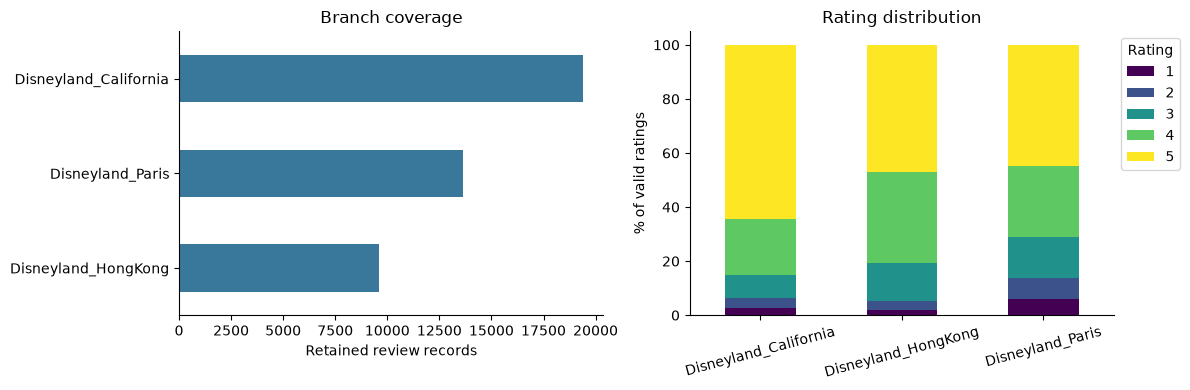

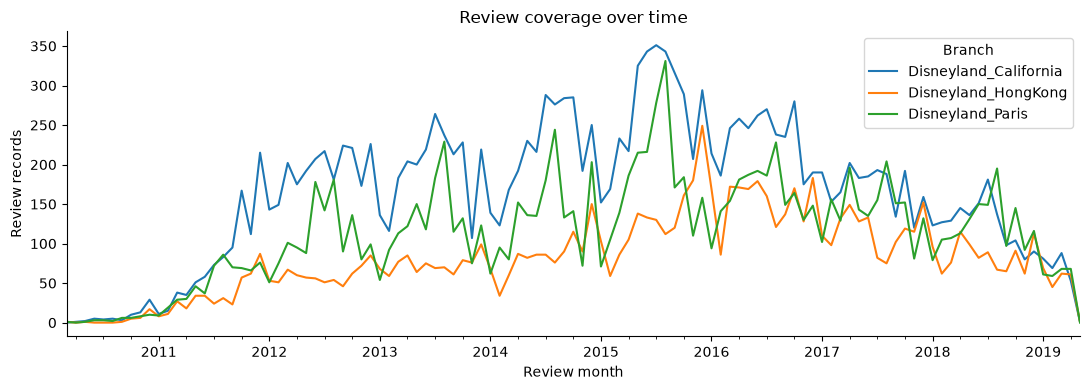

In [6]:
branch_summary = df.groupby("Branch").agg(
    reviews=("row_id", "size"),
    valid_ratings=("rating", "count"),
    mean_rating=("rating", "mean"),
    median_rating=("rating", "median"),
    first_month=("review_month", "min"),
    last_month=("review_month", "max"),
)
branch_summary["share_pct"] = 100 * branch_summary["reviews"] / len(df)
rating_counts = pd.crosstab(df["Branch"], df["rating"]).reindex(
    columns=[1, 2, 3, 4, 5], fill_value=0
)
rating_pct = rating_counts.div(rating_counts.sum(axis=1), axis=0) * 100
location_counts = df["Reviewer_Location"].value_counts()
location_coverage = pd.crosstab(df["Reviewer_Location"], df["Branch"])
location_branch = (
    df.groupby(["Branch", "Reviewer_Location"])
    .agg(reviews=("row_id", "size"), mean_rating=("rating", "mean"))
    .reset_index()
)
location_branch["small_group"] = location_branch["reviews"] < 30
display(branch_summary.round(2))
display(rating_pct.round(1))
display(location_coverage.loc[location_counts.head(10).index])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
branch_summary["reviews"].sort_values().plot.barh(ax=axes[0], color="#39789b")
axes[0].set(
    xlabel="Retained review records", ylabel="", title="Branch coverage"
)
rating_pct.plot.bar(stacked=True, ax=axes[1], rot=15, colormap="viridis")
axes[1].set(
    ylabel="% of valid ratings", xlabel="", title="Rating distribution"
)
axes[1].legend(title="Rating", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

monthly = (
    df.dropna(subset=["review_month"])
    .groupby(["review_month", "Branch"])
    .size()
    .unstack(fill_value=0)
)
if not monthly.empty:
    monthly.plot(title="Review coverage over time", figsize=(11, 4))
    plt.ylabel("Review records")
    plt.xlabel("Review month")
    plt.tight_layout()
    plt.show()


In [7]:
display(Markdown(f"""### Findings and interpretation

**{branch_summary['reviews'].idxmax()}** supplies the largest share of
the retained sample at **{branch_summary['share_pct'].max():.1f}%**,
while **{100 * df['rating'].ge(4).sum() / df['rating'].count():.1f}%**
of valid ratings are four or five stars. The generally favorable ratings
therefore provide context for the complaint analysis, because criticism
of one part of a visit need not imply a poor overall experience. The
most common stated reviewer location is **{location_counts.index[0]}**,
which accounts for **{100 * location_counts.iloc[0] / len(df):.1f}%** of
records, and **{location_branch['small_group'].sum():,}** observed
branch-location groups contain fewer than 30 reviews. These imbalances
mean that raw complaint totals and small location-group averages should
not be treated as comparable measures of park quality. The time plot
also describes historical review coverage rather than current operating
conditions."""))


### Findings and interpretation

**Disneyland_California** supplies the largest share of
the retained sample at **45.5%**,
while **79.5%**
of valid ratings are four or five stars. The generally favorable ratings
therefore provide context for the complaint analysis, because criticism
of one part of a visit need not imply a poor overall experience. The
most common stated reviewer location is **United States**,
which accounts for **34.1%** of
records, and **290** observed
branch-location groups contain fewer than 30 reviews. These imbalances
mean that raw complaint totals and small location-group averages should
not be treated as comparable measures of park quality. The time plot
also describes historical review coverage rather than current operating
conditions.

## 4. Word vectorization
We retain the group draft's 5,000-feature limit and TF-IDF inspection, while adding the class notebook's `CountVectorizer` representation. Both matrices use the same vocabulary and row order, and the vocabulary is fitted once across the corpus so branch comparisons remain on the same scale. English stopwords are removed except for negation terms, while a separate bigram table retains stopwords to preserve phrases. We use scikit-learn's smoothed IDF and L2 normalization, so the values are not a literal calculation of the unsmoothed formula shown in the slides.

In [8]:
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "cannot"})
count_vectorizer = CountVectorizer(
    lowercase=False,
    stop_words=stop_words,
    token_pattern=r"\w+",
    min_df=5,
    max_df=0.95,
    max_features=5000,
)
docs = text_df["clean_text"]
bow = count_vectorizer.fit_transform(docs)
terms = count_vectorizer.get_feature_names_out()
# The fixed vocabulary carries the 5,000-feature cap into TF-IDF.
tfidf_vectorizer = TfidfVectorizer(
    vocabulary=count_vectorizer.vocabulary_,
    lowercase=False,
    stop_words=stop_words,
    token_pattern=r"\w+",
)
tfidf_matrix = tfidf_vectorizer.fit_transform(docs)
term_summary = pd.DataFrame(
    {
        "term": terms,
        "occurrences": np.asarray(bow.sum(axis=0)).ravel(),
        "review_count": np.asarray((bow > 0).sum(axis=0)).ravel(),
        "total_tfidf": np.asarray(tfidf_matrix.sum(axis=0)).ravel(),
        "mean_tfidf": np.asarray(tfidf_matrix.mean(axis=0)).ravel(),
    }
).sort_values("total_tfidf", ascending=False)
sparsity = 100 * (1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape))
print("TF-IDF matrix:", tfidf_matrix.shape, "| sparsity:", round(sparsity, 2))
display(term_summary.head(15).round(3))
first = tfidf_matrix.getrow(0)
first_terms = pd.DataFrame({"term": terms[first.indices], "tfidf": first.data})
display(first_terms.sort_values("tfidf", ascending=False).head(10).round(3))

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2), min_df=5, max_features=5000
)
bigram_matrix = bigram_vectorizer.fit_transform(docs)
bigram_summary = pd.DataFrame(
    {
        "phrase": bigram_vectorizer.get_feature_names_out(),
        "review_count": np.asarray((bigram_matrix > 0).sum(axis=0)).ravel(),
    }
).sort_values("review_count", ascending=False)
display(bigram_summary.head(15))

branch_term_tables = []
for branch in sorted(text_df["Branch"].unique()):
    mask = text_df["Branch"].eq(branch).to_numpy()
    branch_mean = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()
    other_mean = (
        np.asarray(tfidf_matrix[~mask].mean(axis=0)).ravel()
        if (~mask).any()
        else np.full(len(terms), np.nan)
    )
    table = pd.DataFrame(
        {
            "Branch": branch,
            "term": terms,
            "mean_tfidf": branch_mean,
            "difference_from_other_branches": branch_mean - other_mean,
        }
    )
    branch_term_tables.append(table)
branch_terms = pd.concat(branch_term_tables, ignore_index=True)
top_branch_terms = (
    branch_terms.sort_values("difference_from_other_branches", ascending=False)
    .groupby("Branch")
    .head(6)
)
display(top_branch_terms.round(4))


TF-IDF matrix: (42644, 5000) | sparsity: 99.07


,term,occurrences,review_count,total_tfidf,mean_tfidf
2997,not,62322,25540,2377.930,0.056
3163,park,45342,21425,2003.878,0.047
1376,disney,37134,18983,1785.603,0.042
1377,disneyland,33555,19792,1753.810,0.041
3715,rides,35002,20676,1721.017,0.040
4495,time,29895,17741,1560.515,0.037
1239,day,28907,16476,1529.194,0.036
3779,s,25864,13762,1407.518,0.033
2032,great,16630,12075,1277.286,0.030
3278,place,13586,10488,1124.379,0.026


,term,tfidf
6,fairly,0.472
7,familiar,0.269
12,layout,0.266
17,relatively,0.245
15,moved,0.239
5,fabulous,0.215
19,similar,0.214
4,doing,0.192
0,absolutely,0.176
13,ll,0.173


,phrase,review_count
2676,of the,15608
3778,the park,14867
1868,in the,13109
2064,it was,12253
328,and the,10922
1413,for the,10237
1781,if you,9791
4221,to the,9317
3815,the rides,9095
531,at the,8148


,Branch,term,mean_tfidf,difference_from_other_branches
7209,Disneyland_HongKong,hong,0.0389,0.0383
7504,Disneyland_HongKong,kong,0.0389,0.0382
13162,Disneyland_Paris,paris,0.0347,0.0317
7187,Disneyland_HongKong,hk,0.0294,0.0292
13494,Disneyland_Paris,queues,0.0253,0.0186
2621,Disneyland_California,lines,0.0245,0.0165
753,Disneyland_California,california,0.0201,0.0164
9046,Disneyland_HongKong,small,0.0256,0.0161
7916,Disneyland_HongKong,mtr,0.0151,0.0151
13491,Disneyland_Paris,queue,0.0206,0.0145


In [9]:
display(Markdown(f"""### Findings and interpretation

The shared representation contains **{tfidf_matrix.shape[1]:,} terms**
and is **{sparsity:.2f}% sparse**, so retaining it as a sparse matrix
avoids allocating a large table of mostly zeros. The terms with the
largest total TF-IDF weights are
**{', '.join(term_summary.head(5)['term'])}**, while the first review is
particularly represented by
**{', '.join(first_terms.nlargest(3, 'tfidf')['term'])}**. These
summaries answer different questions: the former reflects weight across
the corpus, whereas the latter describes one review. Within a fixed
corpus, total and mean TF-IDF produce the same ordering, but neither is
a sentiment score. The branch contrasts suggest vocabulary to inspect in
context, although prominent words and bigrams do not independently
establish a complaint, and bigrams may cross punctuation boundaries
after cleaning."""))


### Findings and interpretation

The shared representation contains **5,000 terms**
and is **99.07% sparse**, so retaining it as a sparse matrix
avoids allocating a large table of mostly zeros. The terms with the
largest total TF-IDF weights are
**not, park, disney, disneyland, rides**, while the first review is
particularly represented by
**fairly, familiar, layout**. These
summaries answer different questions: the former reflects weight across
the corpus, whereas the latter describes one review. Within a fixed
corpus, total and mean TF-IDF produce the same ordering, but neither is
a sentiment score. The branch contrasts suggest vocabulary to inspect in
context, although prominent words and bigrams do not independently
establish a complaint, and bigrams may cross punctuation boundaries
after cleaning.

## 5. Attraction mentions, complaints and sentiment

We look for attraction and service names, then check nearby words for a specific problem. For example, “staff were rude” becomes a staff-service complaint, while “staff were helpful” does not. We keep the matched phrase and its surrounding text so we can check how each label was assigned.

VADER separately scores the surrounding sentence or clause. Its label describes that text, so it can be positive or neutral even when our rules find a complaint. We keep both results rather than treating either one as a perfect reading of the review.

FIM will look for complaints that appear together naturally. We exclude the extra “Dining with queue/crowd mentions” label because our code creates it from other labels; including it alongside those labels would make FIM report a relationship we already built into the data. Independent complaints can still be mined together.

Tables in Sections 5–10 show at most five rows, while the CSV exports contain the complete results. The findings describe the supplied dataset and should be updated if the data or rules change.

In [10]:
from IPython.display import HTML

# store named attractions so generic words don't identify them

ATTRACTIONS = {
    "Space Mountain": ["space mountain", "hyperspace mountain"],
    "It's a Small World": [
        "it's a small world",
        "its a small world",
        "small world",
    ],
    "Pirates of the Caribbean": ["pirates of the caribbean"],
    "Big Thunder Mountain": ["big thunder mountain", "thunder mountain"],
    "Buzz Lightyear": ["buzz lightyear"],
    "Haunted Mansion": ["haunted mansion"],
    "Phantom Manor": ["phantom manor"],
    "Jungle Cruise": ["jungle cruise", "jungle river cruise"],
    "Iron Man Experience": ["iron man experience", "ironman experience"],
    "Mystic Manor": ["mystic manor"],
    "Ratatouille": ["ratatouille"],
    "Dumbo": ["dumbo"],
    "Railroad": ["disneyland railroad", "disney railroad"],
}

# store service categories

SERVICES = {
    "Staff / customer service": [
        "staff",
        "cast member",
        "cast members",
        "customer service",
        "employees",
    ],
    "Food / dining": [
        "food",
        "restaurant",
        "restaurants",
        "food counter",
        "food counters",
        "meal",
        "meals",
        "dining",
    ],
    "Tickets / admission": ["ticket", "tickets", "admission", "entry fee"],
    "Queue / fast pass": [
        "queue",
        "queues",
        "waiting time",
        "wait time",
        "fastpass",
        "fast pass",
    ],
    "Cleanliness / toilets": [
        "toilet",
        "toilets",
        "restroom",
        "restrooms",
        "bathroom",
        "bathrooms",
        "cleanliness",
    ],
    "Shows / entertainment": ["parade", "parades", "fireworks", "shows"],
    "Transport / parking": ["parking", "shuttle", "shuttles", "transport"],
}

SERVICES["Hotel / accommodation"] = ["hotel", "hotels", "room", "rooms"]
SERVICES["Transport / access"] = [
    "shuttle",
    "bus",
    "buses",
    "mtr",
    "train",
    "parking",
]


def show_table(
    table,
    title,
    note="",
    percent_columns=(),
    labels=None,
    empty_message="No rows are available for this comparison.",
):
    """Show five labeled rows; leave the complete analysis table unchanged."""
    display(Markdown(f"**{title}**"))
    if note:
        display(Markdown(note))
    if table.empty:
        display(Markdown(empty_message))
        return
    preview = table.head(5).copy().reset_index(drop=True)
    shortened = False
    for column in preview.columns:
        if preview[column].dtype == "object" or pd.api.types.is_string_dtype(
            preview[column]
        ):
            preview[column] = preview[column].map(
                lambda value: (
                    " + ".join(sorted(value))
                    if isinstance(value, (set, tuple, list))
                    else value
                )
            )
            long_text = preview[column].map(
                lambda value: isinstance(value, str) and len(value) > 240
            )
            shortened = shortened or long_text.any()
            preview.loc[long_text, column] = (
                preview.loc[long_text, column].str.slice(0, 237) + "..."
            )
        if pd.api.types.is_bool_dtype(preview[column]):
            preview[column] = preview[column].map({True: "Yes", False: "No"})
    if "Branch" in preview:
        preview["Branch"] = preview["Branch"].replace(
            {
                "Disneyland_California": "California",
                "Disneyland_HongKong": "Hong Kong",
                "Disneyland_Paris": "Paris",
            }
        )
    names = {
        column: str(column).replace("_", " ").capitalize()
        for column in preview.columns
    }
    names.update(labels or {})
    preview = preview.rename(columns=names)
    formats = {
        names[column]: lambda value: f"{value:.2%}"
        for column in percent_columns
    }
    display(Markdown(f"Showing {len(preview)} of {len(table)} rows."))
    if shortened:
        display(
            Markdown(
                "Long text is shortened here; full text is saved in the CSV"
                " files."
            )
        )
    display(
        HTML(
            preview.to_html(
                index=False,
                escape=True,
                na_rep="Not available",
                border=0,
                float_format=lambda value: f"{value:,.3f}",
                formatters=formats,
                justify="left",
            )
        )
    )


In [11]:
def compile_aliases(dictionary):
    """Compile complete-word aliases for each attraction or service label."""
    patterns = {}
    for label, aliases in dictionary.items():
        alternatives = [
            re.escape(alias)
            for alias in sorted(aliases, key=len, reverse=True)
        ]
        patterns[label] = re.compile(
            r"\b(?:" + "|".join(alternatives) + r")\b", re.I
        )
    return patterns


def find_labels(text, patterns):
    """Return the labels whose aliases occur in a text segment."""
    return [
        label for label, pattern in patterns.items() if pattern.search(text)
    ]


def nearby_patterns(topic, cue):
    """Connect topic and cue through at most four ordinary linking words."""
    links = (
        r"is|are|was|were|be|been|being|very|quite|really|so|too|"
        r"all|the|a|bit|generally|extremely|absolutely|which|that|"
        r"either|still|often|sometimes|not|never|only|"
        r"at|in|of|quality|attitude"
    )
    # Restrict the gap so it cannot jump across another aspect or a comma.
    gap = r"(?:\s+(?:" + links + r")){0,4}\s+"
    first = r"\b(?:" + topic + r")\b" + gap + r"(?P<cue>" + cue + r")\b"
    second = r"\b(?P<cue>" + cue + r")\b" + gap + r"(?:" + topic + r")\b"
    return [re.compile(first, re.I), re.compile(second, re.I)]


attraction_patterns = compile_aliases(ATTRACTIONS)
service_patterns = compile_aliases(SERVICES)
ride_topics = r"rides?|attractions?|roller\s*coasters?|" + "|".join(
    re.escape(alias) for aliases in ATTRACTIONS.values() for alias in aliases
)
# Each category requires an explicit cue, rather than general negativity.
COMPLAINT_RULES = {
    "Long queues": nearby_patterns(
        r"queues?|lines?|waits?|waiting",
        r"long|lengthy|slow|huge|massive|horrendous|awful",
    ),
    "Closures / breakdowns": nearby_patterns(
        ride_topics,
        r"closed|broken\s+down|broke\s+down|not\s+working|"
        r"out\s+of\s+service|under\s+maintenance|shut\s+down",
    ),
    "Poor staff service": nearby_patterns(
        r"staff|cast\s+members?|employees?|service",
        r"rude|unhelpful|unfriendly|impolite|poor|terrible|awful",
    ),
    "High prices / poor value": [
        re.compile(
            r"\b(?P<cue>too\s+expensive|very\s+expensive|overpriced|"
            r"poor\s+value|"
            r"waste\s+of\s+money|not\s+worth\s+(?:the\s+)?"
            r"(?:money|price|cost))\b",
            re.I,
        )
    ],
    "Food quality / dining": nearby_patterns(
        r"food|meals?|restaurants?|lunch|dinner|burgers?|pizza",
        r"cold|stale|undercooked|poor|bad|terrible|awful|disgusting",
    ),
    "Crowding": [
        re.compile(
            r"\b(?P<cue>overcrowded|too\s+crowded|very\s+crowded|"
            r"extremely\s+crowded|uncomfortably\s+crowded)\b",
            re.I,
        )
    ],
    "Cleanliness": nearby_patterns(
        r"park|toilets?|restrooms?|bathrooms?|tables?|floors?|restaurant",
        r"dirty|filthy|unclean|disgusting",
    ),
}
COMPLAINT_RULES["Crowding"] += nearby_patterns(
    r"park|parks|crowds?|areas?", r"packed|heaving|rammed|huge"
)
COMPLAINT_RULES["Hotel problems"] = nearby_patterns(
    r"hotels?|rooms?", r"dirty|filthy|noisy|poor|terrible|awful"
)
COMPLAINT_RULES["Transport problems"] = nearby_patterns(
    r"shuttles?|buses?|trains?|mtr|parking",
    r"delayed|unreliable|overcrowded|poor|terrible|awful",
)
PRIMARY_CATEGORIES = sorted(COMPLAINT_RULES)


def negated_cue(text, start):
    """Check a short negation window without treating 'not only' as denial."""
    prefix = text[:start].lower()
    prefix = re.split(r"[.!?;:]|\b(?:but|however|although|yet)\b", prefix)[-1]
    if re.search(r"\bnot\s+that\b", prefix):
        return True
    denial = re.search(
        r"\b(?:don't|doesn't|didn't|do\s+not|does\s+not)\s+have\s+to\b|"
        r"\bno\s+need\s+to\b",
        prefix[-100:],
    )
    if denial:
        return True
    if re.search(
        r"\b(?:didn't|don't|doesn't|not|never)\b[^.!?;]{0,70}"
        r"\b(?:any\s+)?more\s+$",
        prefix,
    ):
        return True
    prefix = re.sub(r"\bnot\s+only\b", "", prefix)
    words = re.findall(r"[\w']+", prefix)[-4:]
    negatives = {
        "no",
        "not",
        "never",
        "without",
        "hardly",
        "cannot",
        "wasn't",
        "weren't",
        "isn't",
        "aren't",
        "don't",
        "didn't",
    }
    return any(word in negatives for word in words)


def detect_complaints(segment):
    """Return one explicit evidence match per complaint category."""
    hits = []
    for category, patterns in COMPLAINT_RULES.items():
        for pattern in patterns:
            accepted = None
            for match in pattern.finditer(segment):
                # Advice elsewhere must not erase a factual complaint.
                local_prefix = re.split(r"[,;.!?]", segment[: match.start()])[
                    -1
                ]
                if re.search(
                    r"^\s*(?:if|unless)\b|\b(?:can|could|would)\s+"
                    r"(?:be|get|see)\b|\bwould\s+(?:probably\s+)?say\b",
                    local_prefix,
                    flags=re.I,
                ):
                    continue
                if negated_cue(segment, match.start("cue")):
                    continue
                # Scheduled closing times are not sufficient closure evidence.
                cue_end = match.end("cue")
                tail = segment[cue_end:]
                if category == "Closures / breakdowns" and re.match(
                    r"\s+at\s+\d", tail, flags=re.I
                ):
                    continue
                accepted = match
                break
            if accepted:
                hits.append(
                    {
                        "category": category,
                        "evidence": accepted.group(),
                        "cue": accepted.group("cue"),
                        "primary": True,
                    }
                )
                break
    dining = service_patterns["Food / dining"].search(segment)
    if dining and any(
        hit["category"] in {"Long queues", "Crowding"} for hit in hits
    ):
        hits.append(
            {
                "category": "Dining with queue/crowd mentions",
                "evidence": segment,
                "cue": "dining with queue/crowding cue",
                "primary": False,
            }
        )
    return hits


def split_segments(text):
    """Split sentences and contrast clauses while preserving punctuation."""
    pieces = re.split(
        r"(?<=[.!?;])\s+|(?<=[.!?;])(?=[A-Z])|"
        r"\b(?:but|however|although|yet)\b",
        text,
        flags=re.I,
    )
    return [piece.strip(" ,;") for piece in pieces if piece.strip(" ,;")]


def sentiment_label(score):
    """Apply the usual VADER compound thresholds to local context."""
    if score >= 0.05:
        return "positive"
    if score <= -0.05:
        return "negative"
    return "neutral"


In [12]:
analyzer = SentimentIntensityAnalyzer()
mention_rows = []
complaint_rows = []
for position, row in enumerate(text_df.itertuples(index=False), start=1):
    for segment_id, segment in enumerate(split_segments(row.sentiment_text)):
        attractions = find_labels(segment, attraction_patterns)
        services = find_labels(segment, service_patterns)
        hits = detect_complaints(segment)
        if not attractions and not services and not hits:
            continue
        score = analyzer.polarity_scores(segment)["compound"]
        common = {
            "row_id": row.row_id,
            "Review_ID": row.Review_ID,
            "Branch": row.Branch,
            "segment_id": segment_id,
            "segment": segment,
            "compound": score,
            "context_sentiment": sentiment_label(score),
        }
        for kind, labels in [
            ("attraction", attractions),
            ("service", services),
        ]:
            for aspect in labels:
                mention_rows.append(
                    {
                        **common,
                        "aspect_type": kind,
                        "aspect": aspect,
                        "multiple_aspects": len(attractions) + len(services)
                        > 1,
                    }
                )
        for hit in hits:
            complaint_rows.append(
                {
                    **common,
                    **hit,
                    "candidate_attraction": (
                        attractions[0] if len(attractions) == 1 else None
                    ),
                    "link_status": (
                        "candidate_same_segment"
                        if len(attractions) == 1
                        else (
                            "ambiguous" if len(attractions) > 1 else "unlinked"
                        )
                    ),
                }
            )
    if position % 10000 == 0:
        print(f"Processed {position:,} reviews")

common_cols = [
    "row_id",
    "Review_ID",
    "Branch",
    "segment_id",
    "segment",
    "compound",
    "context_sentiment",
]
mentions = pd.DataFrame(
    mention_rows,
    columns=common_cols + ["aspect_type", "aspect", "multiple_aspects"],
)
complaints = pd.DataFrame(
    complaint_rows,
    columns=common_cols
    + [
        "category",
        "evidence",
        "cue",
        "primary",
        "candidate_attraction",
        "link_status",
    ],
)
primary_complaints = complaints.loc[complaints["primary"].eq(True)].copy()

# Average within a review before aggregating an aspect across reviews.
aspect_reviews = (
    mentions.groupby(["row_id", "Branch", "aspect_type", "aspect"])
    .agg(
        mean_context_score=("compound", "mean"),
        positive_context=("compound", lambda values: values.ge(0.05).any()),
        negative_context=("compound", lambda values: values.le(-0.05).any()),
    )
    .reset_index()
)
aspect_reviews["mixed_context"] = (
    aspect_reviews["positive_context"] & aspect_reviews["negative_context"]
)
aspect_summary = (
    aspect_reviews.groupby(["Branch", "aspect_type", "aspect"])
    .agg(
        reviews=("row_id", "nunique"),
        mean_context_score=("mean_context_score", "mean"),
        mixed_context_reviews=("mixed_context", "sum"),
    )
    .reset_index()
    .sort_values("reviews", ascending=False)
)
denominators = text_df.groupby("Branch").size().rename("text_reviews")
all_pairs = pd.MultiIndex.from_product(
    [denominators.index, PRIMARY_CATEGORIES], names=["Branch", "category"]
)
complaint_summary = (
    primary_complaints.groupby(["Branch", "category"])["row_id"]
    .nunique()
    .reindex(all_pairs, fill_value=0)
    .rename("reviews")
    .reset_index()
    .merge(denominators, on="Branch")
)
complaint_summary["review_pct"] = (
    100 * complaint_summary["reviews"] / complaint_summary["text_reviews"]
)
show_table(
    aspect_summary,
    "Most mentioned attractions and services",
    "Sentiment averages the contexts within each review before averaging"
    " reviews.",
    labels={
        "reviews": "Reviews mentioning the aspect",
        "mean_context_score": "Mean VADER score (-1 to +1)",
        "mixed_context_reviews": (
            "Reviews with both positive and negative context"
        ),
    },
)
show_table(
    complaint_summary,
    "Detected complaint categories by branch",
    "Percentages use all usable reviews in the branch.",
    labels={
        "reviews": "Reviews with the complaint",
        "text_reviews": "All usable branch reviews",
        "review_pct": "Branch reviews with complaint (%)",
    },
)
show_table(
    primary_complaints[
        [
            "row_id",
            "category",
            "evidence",
            "segment",
            "compound",
            "context_sentiment",
        ]
    ],
    "Complaint evidence and its surrounding sentiment",
    "The phrase triggers the complaint rule; VADER scores the surrounding"
    " text.",
    labels={
        "row_id": "Review row",
        "evidence": "Matched phrase",
        "segment": "Surrounding text",
        "compound": "VADER score (-1 to +1)",
        "context_sentiment": "VADER label for surrounding text",
    },
)

# Save balanced examples for qualitative review without claiming accuracy.
audit_parts = []
for _, group in primary_complaints.groupby(["Branch", "category"]):
    audit_parts.append(group.sample(n=min(10, len(group)), random_state=SEED))
extraction_audit = (
    pd.concat(audit_parts, ignore_index=True)
    if audit_parts
    else primary_complaints.copy()
)
extraction_audit["reviewer_judgment"] = ""
extraction_audit["notes"] = ""
unmatched = text_df.loc[~text_df["row_id"].isin(primary_complaints["row_id"])]
unmatched_audit = unmatched.sample(
    n=min(150, len(unmatched)), random_state=SEED
)[["row_id", "Branch", "Review_Text"]].copy()
unmatched_audit["missed_categories"] = ""
attraction_review_count = mentions.loc[
    mentions["aspect_type"].eq("attraction"), "row_id"
].nunique()


Processed 10,000 reviews


Processed 20,000 reviews


Processed 30,000 reviews


Processed 40,000 reviews


**Most mentioned attractions and services**

...

**Complaint evidence and its surrounding sentiment**

The phrase triggers the complaint rule; VADER scores the surrounding text.

Showing 5 of 12145 rows.

Long text is shortened here; full text is saved in the CSV files.

Review row,Category,Matched phrase,Surrounding text,VADER score (-1 to +1),VADER label for surrounding text
5,High prices / poor value,VERY expensive,was VERY expensive,0.000,neutral
8,Closures / breakdowns,rides were not working,"Feel so let down with this place,the Disneyland train was fantastic until you get past the station,bad signage, terrible staff who just did not want to be there ,it was rainning and rides were not working could not find a map of place, o...",0.554,positive
8,Poor staff service,terrible staff,"Feel so let down with this place,the Disneyland train was fantastic until you get past the station,bad signage, terrible staff who just did not want to be there ,it was rainning and rides were not working could not find a map of place, o...",0.554,positive
46,Long queues,long wait,"Some rides had a long wait ie 40 minutes, so skipped them till later in the day ie 4 5pm, and the wait period was down to less than 10minutes.",0.000,neutral
52,Long queues,long queues,Pricey food and somewhat long queues,0.000,neutral


### Findings and interpretation

The rules find explicit problems, while the attraction dictionary shows which names appear nearby. These are useful starting points for reading the reviews, although nearby names do not always identify the target of a complaint.

The first price example, review row 5, says “was VERY expensive.” Its VADER score is 0.000 because “expensive” is not in the installed VADER sentiment dictionary. Our own price rule still recognizes “VERY expensive,” so the complaint label and neutral context label can both appear. Here, neutral means that VADER found no scored sentiment; it does not mean the reviewer had no complaint. The evidence table now shows the text and score together.

### 5.1 Checking the labels and identifying specific targets

We use the TF-IDF terms to decide which topics deserve closer reading, then compare the complaint labels with VADER's results. We also look for direct phrases such as “long food queues” or “Space Mountain was closed,” which give a clearer target than two topics appearing somewhere in the same review.

We save matched examples and a random sample of up to 50 complete reviews per branch for human checking. These files are blank worksheets, so they do not yet measure how accurate the labels are.

In [13]:
# Keep the vocabulary-to-rule decisions visible and reproducible.
TERM_DECISIONS = {
    "hotel": "Hotel problems: require hotel/room beside a problem cue",
    "hotels": "Hotel problems: require hotel/room beside a problem cue",
    "staff": "Poor staff service: require an explicit service cue",
    "queues": "Long queues: require a queue problem expression",
    "mtr": "Transport problems: require a transport problem cue",
    "shuttle": "Transport problems: require a transport problem cue",
}
vocabulary_review = top_branch_terms.copy()
vocabulary_review["decision"] = (
    vocabulary_review["term"]
    .map(TERM_DECISIONS)
    .fillna("Context or place term; no automatic complaint label")
)
show_table(
    vocabulary_review[
        ["Branch", "term", "difference_from_other_branches", "decision"]
    ],
    "TF-IDF terms considered for the complaint rules",
    "A positive difference means the term has higher average TF-IDF in this"
    " branch.",
    labels={
        "difference_from_other_branches": (
            "TF-IDF difference from other branches"
        )
    },
)

sentiment_diagnostic = (
    primary_complaints.assign(
        positive_context=primary_complaints["context_sentiment"].eq("positive")
    )
    .groupby(["Branch", "category"])
    .agg(
        matched_segments=("row_id", "size"),
        positive_segments=("positive_context", "sum"),
    )
    .reset_index()
)
sentiment_diagnostic["positive_pct"] = (
    100
    * sentiment_diagnostic["positive_segments"]
    / sentiment_diagnostic["matched_segments"]
)
show_table(
    sentiment_diagnostic.sort_values("positive_pct", ascending=False),
    "Complaint matches with positive VADER context",
    "These are category-segment matches, not unique reviews or an error rate.",
    labels={
        "matched_segments": "All matched segments",
        "positive_segments": "Matches with positive context",
        "positive_pct": "Positive-context matches (%)",
    },
)

TARGET_RULES = {
    "Dining:queue": nearby_patterns(
        r"food\s+(?:queues?|lines?)|restaurant\s+(?:queues?|lines?)",
        r"long|slow|huge|horrendous",
    ),
    "Dining:crowding": nearby_patterns(
        r"food\s+counters?|restaurants?|dining\s+areas?",
        r"overcrowded|too\s+crowded|packed",
    ),
    "Tickets:price": nearby_patterns(
        r"tickets?|admission|entry", r"overpriced|too\s+expensive"
    ),
    "Food:price": nearby_patterns(
        r"food|meals?|restaurants?", r"overpriced|too\s+expensive"
    ),
    "Hotel:price": nearby_patterns(
        r"hotels?|rooms?", r"overpriced|too\s+expensive"
    ),
    "Merchandise:price": nearby_patterns(
        r"souvenirs?|merchandise|gifts?", r"overpriced|too\s+expensive"
    ),
}
for attraction, aliases in ATTRACTIONS.items():
    topic = "|".join(re.escape(alias) for alias in aliases)
    TARGET_RULES[attraction + ":closure"] = nearby_patterns(
        topic, r"closed|broken\s+down|not\s+working|under\s+maintenance"
    )


def find_target_match(segment, patterns, target):
    """Return the first valid target phrase, including later occurrences."""
    for pattern in patterns:
        for match in pattern.finditer(segment):
            if negated_cue(segment, match.start("cue")):
                continue
            match_start = match.start()
            prefix = re.split(r"[,;.!?]", segment[:match_start])[-1]
            hypothetical = re.search(
                r"^\s*(?:if|unless)\b|\b(?:can|could|would)\s+"
                r"(?:be|get|see)\b|\bwould\s+(?:probably\s+)?say\b",
                prefix,
                flags=re.I,
            )
            cue_end = match.end("cue")
            scheduled = target.endswith(":closure") and re.match(
                r"\s+at\s+\d", segment[cue_end:], flags=re.I
            )
            if not hypothetical and not scheduled:
                return match
    return None


target_rows = []
segments = pd.concat([mentions[common_cols], complaints[common_cols]])
for row in segments.drop_duplicates(["row_id", "segment_id"]).itertuples():
    for target, patterns in TARGET_RULES.items():
        match = find_target_match(row.segment, patterns, target)
        if match:
            target_rows.append(
                {
                    "row_id": row.row_id,
                    "Branch": row.Branch,
                    "target_item": target,
                    "phrase": match.group(),
                    "segment": row.segment,
                    "context_sentiment": row.context_sentiment,
                }
            )
target_evidence = pd.DataFrame(
    target_rows,
    columns=[
        "row_id",
        "Branch",
        "target_item",
        "phrase",
        "segment",
        "context_sentiment",
    ],
).drop_duplicates(["row_id", "target_item", "segment"])
target_summary = (
    target_evidence.groupby(["Branch", "target_item"])
    .agg(reviews=("row_id", "nunique"))
    .reset_index()
    .merge(denominators, on="Branch")
)
target_summary["review_pct"] = (
    100 * target_summary["reviews"] / target_summary["text_reviews"]
)
target_summary["small_count"] = target_summary["reviews"].lt(20)
show_table(
    target_summary.sort_values("reviews", ascending=False),
    "Direct attraction and service problem phrases",
    labels={
        "reviews": "Reviews with this target phrase",
        "text_reviews": "All usable branch reviews",
        "review_pct": "Branch reviews with target phrase (%)",
        "small_count": "Fewer than 20 reviews?",
    },
)

# A review-level random sample allows all nine categories to be assessed.
# Label every category as present/absent, including currently unmatched ones.
# A smaller branch contributes all its reviews rather than raising an error.
audit_groups = [
    group.sample(n=min(50, len(group)), random_state=SEED + 1)
    for _, group in text_df.groupby("Branch")
]
review_audit = (
    pd.concat(audit_groups, ignore_index=True)[
        ["row_id", "Branch", "Review_Text"]
    ].copy()
    if audit_groups
    else text_df[["row_id", "Branch", "Review_Text"]].copy()
)
for category in PRIMARY_CATEGORIES:
    review_audit["human: " + category] = ""
review_audit["reviewer_notes"] = ""


**TF-IDF terms considered for the complaint rules**

A positive difference means the term has higher average TF-IDF in this branch.

Showing 5 of 18 rows.

Branch,Term,TF-IDF difference from other branches,Decision
Hong Kong,hong,0.038,Context or place term; no automatic complaint label
Hong Kong,kong,0.038,Context or place term; no automatic complaint label
Paris,paris,0.032,Context or place term; no automatic complaint label
Hong Kong,hk,0.029,Context or place term; no automatic complaint label
Paris,queues,0.019,Long queues: require a queue problem expression


**Complaint matches with positive VADER context**

...

Showing 5 of 25 rows.

Branch,Category,All matched segments,Matches with positive context,Positive-context matches (%)
California,Hotel problems,2,1,50.000
Paris,Crowding,345,166,48.116
Hong Kong,Crowding,215,94,43.721
Hong Kong,Closures / breakdowns,147,58,39.456
Hong Kong,Long queues,725,285,39.310


**Direct attraction and service problem phrases**

Showing 5 of 39 rows.

Branch,Target item,Reviews with this target phrase,All usable branch reviews,Branch reviews with target phrase (%),Fewer than 20 reviews?
Paris,Food:price,87,13629,0.638,No
California,Food:price,61,19404,0.314,No
Paris,Space Mountain:closure,58,13629,0.426,No
Paris,Big Thunder Mountain:closure,43,13629,0.316,No
California,It's a Small World:closure,37,19404,0.191,No


### Findings and interpretation

Some detected complaints appear in positive VADER text, which can happen when a reviewer describes a problem but still praises the visit. These cases deserve a closer read rather than automatic removal.

The direct phrases provide more specific leads for checking attractions and services. Small counts are marked because a few examples are not enough to describe a recurring problem. The human review sample remains unfinished, so these results describe detected wording rather than every complaint in the data.

## 6. Frequent itemsets and association rules

We turn each review into a set of complaint categories and run Apriori separately for each branch. Repeated mentions count once within a review, while separate reviews remain separate baskets.

The `apriori` and `assoc` functions follow the class notebook: support is a review count, and each rule has one category on its right-hand side. We keep empty and single-category baskets because we want percentages out of all usable reviews. This is the deliberate difference from filtering small baskets in the retail example.

A frequent combination must appear in at least 1% of the branch's reviews and at least 30 reviews. A selected rule must also reach 30% confidence and 1.2 lift. The tables show counts and percentages together, and an explanation replaces any empty result table.

In [14]:
MIN_SUPPORT = 0.01
MIN_COUNT = 30
MIN_CONFIDENCE = 0.30
MIN_LIFT = 1.20
category_lists = primary_complaints.groupby("row_id")["category"].agg(
    lambda values: sorted(set(values))
)
baskets_df = text_df[
    [
        "row_id",
        "Review_ID",
        "Branch",
        "Reviewer_Location",
        "rating",
        "word_count",
        "repeated_id",
    ]
].copy()
baskets_df["basket"] = baskets_df["row_id"].apply(
    lambda row_id: set(category_lists.get(row_id, []))
)
baskets_df["basket_size"] = baskets_df["basket"].str.len()
basket_coverage = baskets_df.groupby("Branch").agg(
    reviews=("row_id", "size"),
    empty=("basket_size", lambda sizes: sizes.eq(0).sum()),
    singleton=("basket_size", lambda sizes: sizes.eq(1).sum()),
    multiple=("basket_size", lambda sizes: sizes.ge(2).sum()),
)
basket_coverage["min_count"] = basket_coverage["reviews"].apply(
    lambda total: max(MIN_COUNT, ceil(MIN_SUPPORT * total))
)
show_table(
    basket_coverage.reset_index(),
    "Review baskets and minimum counts by branch",
    labels={
        "reviews": "All review baskets",
        "empty": "No detected complaints",
        "singleton": "One complaint category",
        "multiple": "Two or more categories",
        "min_count": "Minimum frequent-itemset count",
    },
)


def support_count(db, itemset):
    """Count transactions that contain every item in an itemset."""
    wanted = set(itemset)
    return sum(wanted.issubset(transaction) for transaction in db)


def apriori(db, minsup):
    """Return all frequent itemsets with absolute support, in class order."""
    if minsup < 1:
        raise ValueError("Minimum absolute support must be positive.")
    items = sorted({item for transaction in db for item in transaction})
    candidates = [(item,) for item in items]
    frequent = []
    size = 1
    while candidates:
        level = []
        for itemset in candidates:
            count = support_count(db, itemset)
            if count >= minsup:
                level.append((itemset, count))
        frequent.extend(level)
        if not level:
            break
        previous = {itemset for itemset, count in level}
        next_candidates = set()
        for first, second in combinations(sorted(previous), 2):
            if first[:-1] != second[:-1]:
                continue
            joined = tuple(sorted(set(first) | set(second)))
            if len(joined) == size + 1 and all(
                subset in previous for subset in combinations(joined, size)
            ):
                next_candidates.add(joined)
        candidates = sorted(next_candidates)
        size += 1
    return sorted(
        frequent, key=lambda result: (-result[1], -len(result[0]), result[0])
    )


def assoc(fi, minconf, db_size):
    """Return single-consequent rules with class-style counts and ordering."""
    if not 0 <= minconf <= 1:
        raise ValueError("Minimum confidence must be between zero and one.")
    if db_size <= 0:
        return []
    counts = dict(fi)
    rules = []
    for itemset, count in fi:
        if len(itemset) < 2:
            continue
        for consequent in itemset:
            antecedent = tuple(item for item in itemset if item != consequent)
            confidence = count / counts[antecedent]
            if confidence >= minconf:
                rules.append(
                    {
                        "antecedent": antecedent,
                        "consequent": consequent,
                        "support": count,
                        "confidence": confidence,
                        "lift": confidence / (counts[(consequent,)] / db_size),
                    }
                )
    return sorted(
        rules,
        key=lambda rule: (
            -rule["lift"],
            -rule["confidence"],
            -rule["support"],
            rule["consequent"],
            rule["antecedent"],
        ),
    )


**Review baskets and minimum counts by branch**

Showing 3 of 3 rows.

Branch,All review baskets,No detected complaints,One complaint category,Two or more categories,Minimum frequent-itemset count
California,19404,15654,3166,584,195
Hong Kong,9611,8312,1188,111,97
Paris,13629,9431,3254,944,137


In [15]:
branch_baskets = {
    branch: group["basket"].tolist()
    for branch, group in baskets_df.groupby("Branch")
    if branch != "Unknown"
}
itemset_rows = []
rule_rows = []
for branch, db in branch_baskets.items():
    minimum = max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
    frequent = apriori(db, minimum)
    for itemset, count in frequent:
        itemset_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "size": len(itemset),
                "support": count,
                "relative_support": count / len(db),
                "total_reviews": len(db),
            }
        )
    for rule in assoc(frequent, MIN_CONFIDENCE, len(db)):
        if rule["lift"] >= MIN_LIFT:
            rule_rows.append(
                {
                    "Branch": branch,
                    **rule,
                    "relative_support": rule["support"] / len(db),
                    "total_reviews": len(db),
                }
            )
frequent_itemsets = pd.DataFrame(
    itemset_rows,
    columns=[
        "Branch",
        "itemset",
        "size",
        "support",
        "relative_support",
        "total_reviews",
    ],
)
selected_rules = pd.DataFrame(
    rule_rows,
    columns=[
        "Branch",
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "relative_support",
        "total_reviews",
    ],
)
selected_rules["rule"] = [
    " + ".join(a) + " → " + b
    for a, b in zip(selected_rules["antecedent"], selected_rules["consequent"])
]
for branch in branch_baskets:

    show_table(
        frequent_itemsets.loc[
            frequent_itemsets["Branch"].eq(branch)
            & frequent_itemsets["size"].ge(2),
            ["itemset", "support", "relative_support", "total_reviews"],
        ],
        branch.replace("Disneyland_", "")
        + ": frequent complaint combinations",
        percent_columns=["relative_support"],
        labels={
            "itemset": "Complaint combination",
            "support": "Reviews with combination",
            "relative_support": "Share of branch reviews",
            "total_reviews": "All branch reviews",
        },
        empty_message=(
            "No complaint combination meets both the 1% support and 30-review"
            " minimum. Single categories may still be frequent."
        ),
    )
    show_table(
        selected_rules.loc[
            selected_rules["Branch"].eq(branch),
            ["rule", "support", "relative_support", "confidence", "lift"],
        ],
        branch.replace("Disneyland_", "") + ": rules passing all cutoffs",
        percent_columns=["relative_support", "confidence"],
        labels={
            "support": "Reviews with both sides",
            "relative_support": "Share of branch reviews",
            "confidence": "Confidence: right side given left side",
            "lift": "Lift (times baseline)",
        },
        empty_message=(
            "No rule meets the support, confidence and lift cutoffs together."
            " This does not mean the categories never occur together."
        ),
    )


**California: frequent complaint combinations**

No complaint combination meets both the 1% support and 30-review minimum. Single categories may still be frequent.

**California: rules passing all cutoffs**

No rule meets the support, confidence and lift cutoffs together. This does not mean the categories never occur together.

**HongKong: frequent complaint combinations**

...

**Paris: frequent complaint combinations**

Showing 3 of 3 rows.

Complaint combination,Reviews with combination,Share of branch reviews,All branch reviews
High prices / poor value + Long queues,248,1.82%,13629
Closures / breakdowns + Long queues,227,1.67%,13629
Closures / breakdowns + High prices / poor value,190,1.39%,13629


**Paris: rules passing all cutoffs**

No rule meets the support, confidence and lift cutoffs together. This does not mean the categories never occur together.

### Findings and interpretation

Paris has three frequent complaint pairs, while California and Hong Kong have frequent single categories but no pair reaching the 1% cutoff. The most common Paris pair is high prices and long queues, appearing in 248 reviews, or 1.82% of its usable reviews. This gives us a concrete group of comments to examine for how visitors discuss cost and waiting together.

No broad complaint rule meets all the selected cutoffs. For example, 19.39% of Paris reviews with a price complaint also mention long queues, which falls below the 30% confidence requirement. The pair is still frequent; it simply does not qualify as a selected rule. We report this result without changing the thresholds to force more rules.

## 7. Comparing branches and checking the cutoffs

We count the same complaint pairs in every branch, even where they were not frequent enough to be selected. This lets us compare their percentages without confusing “below the cutoff” with “never appeared.”

We also repeat mining at 0.5%, 1% and 2% support, then check whether excluding conflicting review IDs changes the selected rules. These checks show how much the results depend on our choices.

**Both directions of frequent pairs, recounted across branches**

Showing 5 of 18 rows.

Branch,If the review mentions,It also mentions,Reviews mentioning both,Conditional share,Lift (times baseline),Passes all cutoffs?
Paris,High prices / poor value,Long queues,248,19.39%,1.637,No
Paris,Long queues,High prices / poor value,248,15.37%,1.637,No
Paris,Closures / breakdowns,Long queues,227,15.94%,1.346,No
Paris,Long queues,Closures / breakdowns,227,14.06%,1.346,No
Paris,High prices / poor value,Closures / breakdowns,190,14.86%,1.422,No


**The same complaint combinations in every branch**

Each value is the percentage of all usable reviews in that branch.

Showing 3 of 3 rows.

Branch,Pattern,California (%),Hong Kong (%),Paris (%)
,High prices / poor value + Long queues,0.644,0.343,1.820
,Closures / breakdowns + Long queues,0.783,0.042,1.666
,Closures / breakdowns + High prices / poor value,0.253,0.094,1.394


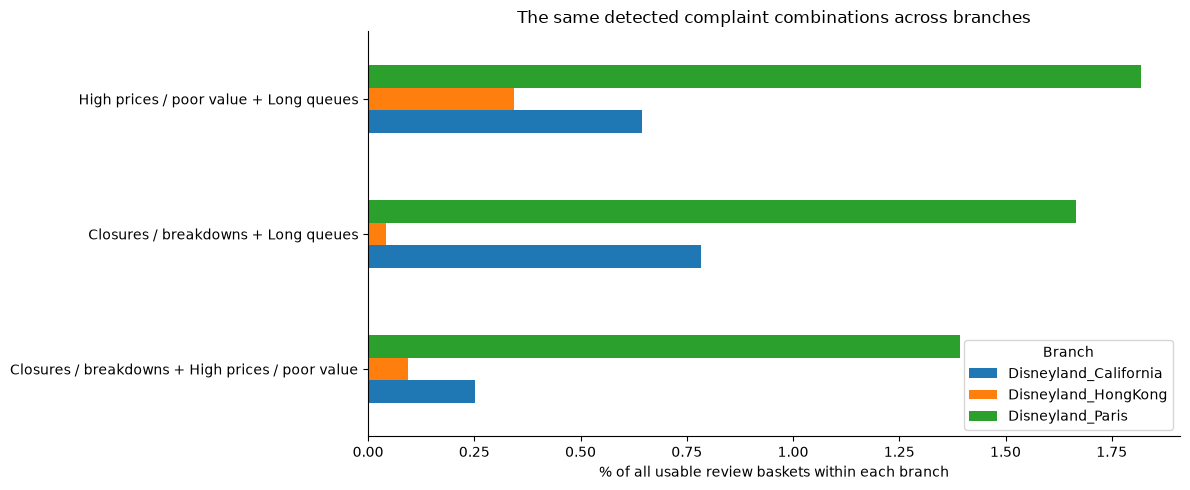

**Number of frequent combinations at different support cutoffs**

The 30-review minimum remains in effect at every cutoff.

Showing 3 of 3 rows.

min_relative_support,Branch,At 0.5% support,At 1% support,At 2% support
,California,3,0,0
,Hong Kong,0,0,0
,Paris,4,3,0


**Rules after removing conflicting review IDs**

Showing 3 of 3 rows.

Branch,Rules before removal,Rules after removal,Rules lost,Rules added
California,0,0,0,0
Hong Kong,0,0,0,0
Paris,0,0,0,0


In [16]:
shared_sets = sorted(
    set(frequent_itemsets.loc[frequent_itemsets["size"].ge(2), "itemset"])
)
comparison_rows = []
for itemset in shared_sets:
    for branch, db in branch_baskets.items():
        count = support_count(db, itemset)
        comparison_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "pattern": " + ".join(itemset),
                "support": count,
                "relative_support": count / len(db),
                "total_reviews": len(db),
            }
        )
itemset_comparison = pd.DataFrame(
    comparison_rows,
    columns=[
        "Branch",
        "itemset",
        "pattern",
        "support",
        "relative_support",
        "total_reviews",
    ],
)

# Compare both directions of every frequent pair, even if no rule passes.
rule_keys = sorted(
    {
        ((first,), second)
        for pair in shared_sets
        if len(pair) == 2
        for first, second in [pair, pair[::-1]]
    }
)
rule_comparison_rows = []
for antecedent, consequent in rule_keys:
    for branch, db in branch_baskets.items():
        joint = support_count(db, set(antecedent) | {consequent})
        a_count = support_count(db, antecedent)
        b_count = support_count(db, {consequent})
        confidence = joint / a_count if a_count else np.nan
        lift = (
            confidence / (b_count / len(db)) if a_count and b_count else np.nan
        )
        rule_comparison_rows.append(
            {
                "Branch": branch,
                "antecedent": antecedent,
                "consequent": consequent,
                "support": joint,
                "antecedent_count": a_count,
                "consequent_count": b_count,
                "relative_support": joint / len(db),
                "confidence": confidence,
                "lift": lift,
                "passes_thresholds": joint
                >= max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
                and confidence >= MIN_CONFIDENCE
                and lift >= MIN_LIFT,
            }
        )
rule_comparison = pd.DataFrame(
    rule_comparison_rows,
    columns=[
        "Branch",
        "antecedent",
        "consequent",
        "support",
        "antecedent_count",
        "consequent_count",
        "relative_support",
        "confidence",
        "lift",
        "passes_thresholds",
    ],
)
show_table(
    rule_comparison.sort_values("support", ascending=False)[
        [
            "Branch",
            "antecedent",
            "consequent",
            "support",
            "confidence",
            "lift",
            "passes_thresholds",
        ]
    ],
    "Both directions of frequent pairs, recounted across branches",
    percent_columns=["confidence"],
    labels={
        "antecedent": "If the review mentions",
        "consequent": "It also mentions",
        "support": "Reviews mentioning both",
        "confidence": "Conditional share",
        "lift": "Lift (times baseline)",
        "passes_thresholds": "Passes all cutoffs?",
    },
)
if not itemset_comparison.empty:
    support_pivot = 100 * itemset_comparison.pivot(
        index="pattern", columns="Branch", values="relative_support"
    )
    top_patterns = support_pivot.max(axis=1).nlargest(5).index
    show_table(
        support_pivot.loc[top_patterns].reset_index(),
        "The same complaint combinations in every branch",
        "Each value is the percentage of all usable reviews in that branch.",
        labels={
            "Disneyland_California": "California (%)",
            "Disneyland_HongKong": "Hong Kong (%)",
            "Disneyland_Paris": "Paris (%)",
        },
    )
    support_pivot.loc[top_patterns].iloc[::-1].plot.barh(figsize=(12, 5))
    plt.xlabel("% of all usable review baskets within each branch")
    plt.ylabel("")
    plt.title("The same detected complaint combinations across branches")
    plt.tight_layout()
    plt.show()

sensitivity_rows = []
duplicate_sensitivity_rows = []
for branch, db in branch_baskets.items():
    for threshold in [0.005, 0.01, 0.02]:
        frequent = apriori(db, max(MIN_COUNT, ceil(threshold * len(db))))
        rules = assoc(frequent, MIN_CONFIDENCE, len(db))
        sensitivity_rows.append(
            {
                "Branch": branch,
                "min_relative_support": threshold,
                "multi_itemsets": sum(
                    len(items) >= 2 for items, count in frequent
                ),
                "selected_rules": sum(
                    rule["lift"] >= MIN_LIFT for rule in rules
                ),
            }
        )
    clean_db = baskets_df.loc[
        baskets_df["Branch"].eq(branch) & ~baskets_df["repeated_id"], "basket"
    ].tolist()
    clean_fi = apriori(
        clean_db, max(MIN_COUNT, ceil(MIN_SUPPORT * len(clean_db)))
    )
    clean_keys = {
        (rule["antecedent"], rule["consequent"])
        for rule in assoc(clean_fi, MIN_CONFIDENCE, len(clean_db))
        if rule["lift"] >= MIN_LIFT
    }
    original = selected_rules.loc[selected_rules["Branch"].eq(branch)]
    original_keys = set(zip(original["antecedent"], original["consequent"]))
    duplicate_sensitivity_rows.append(
        {
            "Branch": branch,
            "original_rules": len(original_keys),
            "rules_without_repeated_ids": len(clean_keys),
            "removed_rules": len(original_keys - clean_keys),
            "new_rules": len(clean_keys - original_keys),
        }
    )
sensitivity = pd.DataFrame(sensitivity_rows)
duplicate_sensitivity = pd.DataFrame(duplicate_sensitivity_rows)
show_table(
    sensitivity.pivot(
        index="Branch", columns="min_relative_support", values="multi_itemsets"
    ).reset_index(),
    "Number of frequent combinations at different support cutoffs",
    "The 30-review minimum remains in effect at every cutoff.",
    labels={
        0.005: "At 0.5% support",
        0.01: "At 1% support",
        0.02: "At 2% support",
    },
)
show_table(
    duplicate_sensitivity,
    "Rules after removing conflicting review IDs",
    labels={
        "original_rules": "Rules before removal",
        "rules_without_repeated_ids": "Rules after removal",
        "removed_rules": "Rules lost",
        "new_rules": "Rules added",
    },
)


### Findings and interpretation

Price and queue complaints appear together in 1.82% of Paris reviews, compared with 0.64% in California and 0.34% in Hong Kong. Paris therefore has the highest observed share of this pair in our data, making those comments a useful place to start investigating cost and waiting concerns.

At 0.5% support, California has three frequent combinations and Paris has four; at 1%, only Paris has three, and at 2%, none remain. No branch produces a rule meeting all the cutoffs at these settings. Removing conflicting IDs also leaves that rule result unchanged. The pair findings depend on the support cutoff, so we keep the counts visible rather than treating the selected list as a permanent ranking of branches.

## 8. Further checks — optional

### 8.1 Complaints in favorable reviews

We repeat pair mining among four- and five-star reviews to see which problems appear even when visitors rate the trip highly. We then count the same pairs among one- and two-star reviews. Three-star reviews remain in the main analysis but are left out of this high-versus-low comparison.

In [17]:
favorable_pair_rows = []
rating_coverage = (
    baskets_df.assign(
        rating_group=baskets_df["rating"]
        .map({1: "low", 2: "low", 3: "middle", 4: "high", 5: "high"})
        .fillna("missing")
    )
    .groupby(["Branch", "rating_group"])
    .size()
    .unstack(fill_value=0)
)
for branch, group in baskets_df.groupby("Branch"):
    if branch == "Unknown":
        continue
    high_db = group.loc[group["rating"].ge(4), "basket"].tolist()
    low_db = group.loc[group["rating"].le(2), "basket"].tolist()
    if not high_db:
        continue
    frequent = apriori(
        high_db, max(MIN_COUNT, ceil(MIN_SUPPORT * len(high_db)))
    )
    for itemset, high_count in frequent:
        if len(itemset) != 2:
            continue
        low_count = support_count(low_db, itemset)
        favorable_pair_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "pattern": " + ".join(itemset),
                "high_count": high_count,
                "high_total": len(high_db),
                "high_support": high_count / len(high_db),
                "low_count": low_count,
                "low_total": len(low_db),
                "low_support": low_count / len(low_db) if low_db else np.nan,
            }
        )
favorable_pairs = pd.DataFrame(
    favorable_pair_rows,
    columns=[
        "Branch",
        "itemset",
        "pattern",
        "high_count",
        "high_total",
        "high_support",
        "low_count",
        "low_total",
        "low_support",
    ],
)
favorable_pairs["small_low_count"] = favorable_pairs["low_count"].lt(20)
show_table(
    rating_coverage.reset_index(),
    "Number of reviews in each rating group",
    labels={
        "low": "1–2 stars",
        "middle": "3 stars",
        "high": "4–5 stars",
        "missing": "Missing rating",
    },
)
show_table(
    favorable_pairs.sort_values("high_support", ascending=False)[
        [
            "Branch",
            "pattern",
            "high_count",
            "high_total",
            "high_support",
            "low_count",
            "low_total",
            "low_support",
        ]
    ],
    "Frequent pairs in favorable reviews, compared with low ratings",
    "Read each count with its rating-group total. Counts below 20 need"
    " particular caution.",
    percent_columns=["high_support", "low_support"],
    labels={
        "high_count": "4–5 star matches",
        "high_total": "All 4–5 star reviews",
        "high_support": "Share of 4–5 star reviews",
        "low_count": "1–2 star matches",
        "low_total": "All 1–2 star reviews",
        "low_support": "Share of 1–2 star reviews",
    },
)


**Number of reviews in each rating group**

Showing 3 of 3 rows.

rating_group,Branch,4–5 stars,1–2 stars,3 stars
,California,16497,1246,1661
,Hong Kong,7740,508,1363
,Paris,9674,1872,2083


**Frequent pairs in favorable reviews, compared with low ratings**

Read each count with its rating-group total. Counts below 20 need particular caution.

Showing 1 of 1 rows.

Branch,Pattern,4–5 star matches,All 4–5 star reviews,Share of 4–5 star reviews,1–2 star matches,All 1–2 star reviews,Share of 1–2 star reviews
Paris,High prices / poor value + Long queues,104,9674,1.08%,72,1872,3.85%


### Findings and interpretation

In Paris, price and queue complaints occur together in 104 of 9,674 favorable reviews, or 1.08%, compared with 72 of 1,872 low-rating reviews, or 3.85%. The pair appears more often in low-rating reviews, but its presence in favorable reviews shows why the overall rating can miss specific concerns. Reading both groups can help distinguish a small inconvenience from a problem that shaped the whole visit.

### 8.2 Checking review length, location and year

We compare complaint rates within short, medium and long reviews, then look separately at the three largest reviewer-location groups per branch and the available review years. This helps us see whether the overall result hides differences in the kinds of reviews being compared.

The previews show groups with at least 100 reviews, and counts below 20 are flagged. Complete group tables are exported. These are separate comparisons, so they do not remove all differences between branches.

In [18]:
context_df = baskets_df.merge(
    text_df[["row_id", "review_month"]], on="row_id", validate="one_to_one"
)
context_df["length_group"] = pd.cut(
    context_df["word_count"],
    bins=[-1, 50, 150, np.inf],
    labels=["1–50 words", "51–150 words", "151+ words"],
)
context_df["year"] = context_df["review_month"].dt.year.astype("Int64")
context_rows = []
for branch, group in context_df.groupby("Branch"):
    top_locations = group["Reviewer_Location"].value_counts().head(3).index
    for dimension in ["length_group", "Reviewer_Location", "year"]:
        selected = group
        if dimension == "Reviewer_Location":
            selected = group.loc[group[dimension].isin(top_locations)]
        for value, subgroup in selected.groupby(dimension, observed=True):
            for category in PRIMARY_CATEGORIES:
                count = sum(
                    category in basket for basket in subgroup["basket"]
                )
                context_rows.append(
                    {
                        "Branch": branch,
                        "dimension": dimension,
                        "group": str(value),
                        "category": category,
                        "reviews": len(subgroup),
                        "detected": count,
                        "review_pct": 100 * count / len(subgroup),
                        "small_count": count < 20,
                    }
                )
context_comparison = pd.DataFrame(context_rows)
for dimension, title in [
    ("length_group", "Queue complaints by review length"),
    ("Reviewer_Location", "Queue complaints by reviewer location"),
    ("year", "Queue complaints by review year"),
]:
    preview_groups = context_comparison.loc[
        context_comparison["reviews"].ge(100)
        & context_comparison["category"].eq("Long queues")
        & context_comparison["dimension"].eq(dimension),
        [
            "Branch",
            "group",
            "reviews",
            "detected",
            "review_pct",
            "small_count",
        ],
    ]
    show_table(
        preview_groups,
        title,
        "Only groups with at least 100 reviews are previewed; all groups are"
        " exported.",
        labels={
            "group": "Group",
            "reviews": "All reviews in group",
            "detected": "Reviews with queue complaints",
            "review_pct": "Group reviews with queue complaints (%)",
            "small_count": "Fewer than 20 complaint reviews?",
        },
    )


**Queue complaints by review length**

Only groups with at least 100 reviews are previewed; all groups are exported.

Showing 5 of 9 rows.

Branch,Group,All reviews in group,Reviews with queue complaints,Group reviews with queue complaints (%),Fewer than 20 complaint reviews?
California,1–50 words,6811,350,5.139,No
California,51–150 words,8216,719,8.751,No
California,151+ words,4377,773,17.660,No
Hong Kong,1–50 words,3278,120,3.661,No
Hong Kong,51–150 words,4536,299,6.592,No


**Queue complaints by reviewer location**

...

Branch,Group,All reviews in group,Reviews with queue complaints,Group reviews with queue complaints (%),Fewer than 20 complaint reviews?
California,Australia,2448,226,9.232,No
California,Canada,1842,157,8.523,No
California,United States,12337,1172,9.500,No
Hong Kong,Australia,1634,97,5.936,No
Hong Kong,India,1083,80,7.387,No


**Queue complaints by review year**

Only groups with at least 100 reviews are previewed; all groups are exported.

Showing 5 of 27 rows.

Branch,Group,All reviews in group,Reviews with queue complaints,Group reviews with queue complaints (%),Fewer than 20 complaint reviews?
California,2011,953,77,8.080,No
California,2012,2310,162,7.013,No
California,2013,2326,235,10.103,No
California,2014,2643,257,9.724,No
California,2015,3239,301,9.293,No


### Findings and interpretation

Queue complaints are detected more often in longer reviews in each branch. Longer reviews have more space to describe several experiences, so part of a branch's overall complaint rate may reflect how much its reviewers wrote.

The location and year tables provide further context for reading the comments. A reviewer's stated location does not tell us their preferences, and the review year is not necessarily the visit year. We use these tables to guide closer reading rather than explain why a branch has more complaints.

### 8.3 Specific targets and low ratings

First, we mine separate baskets containing direct target phrases, such as a named attraction's closure. We keep them separate from broad complaint categories so a specific closure is not counted as a new discovery simply because it implies a general closure.

Next, we ask how often a complaint appears in a one- or two-star review. We use the same support, confidence and lift calculations, but fix “low rating” as the result on the right-hand side. All valid ratings, including three stars, belong in this comparison's baseline.

In [19]:
target_lists = target_evidence.groupby("row_id")["target_item"].agg(set)
target_itemset_rows = []
for branch, group in baskets_df.groupby("Branch"):
    if branch == "Unknown":
        continue
    db = [set(target_lists.get(key, set())) for key in group["row_id"]]
    minimum = max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
    for itemset, count in apriori(db, minimum):
        target_itemset_rows.append(
            {
                "Branch": branch,
                "itemset": itemset,
                "size": len(itemset),
                "support": count,
                "relative_support": count / len(db),
            }
        )
target_itemsets = pd.DataFrame(
    target_itemset_rows,
    columns=[
        "Branch",
        "itemset",
        "size",
        "support",
        "relative_support",
    ],
)
show_table(
    target_itemsets,
    "Frequent direct target items and combinations",
    percent_columns=["relative_support"],
    labels={
        "itemset": "Target item or combination",
        "size": "Number of items",
        "support": "Matching reviews",
        "relative_support": "Share of branch reviews",
    },
    empty_message=(
        "No direct target item or combination meets the 1% support and"
        " 30-review minimum. The phrase evidence is still saved for"
        " inspection."
    ),
)

rating_rule_rows = []
for branch, group in baskets_df.groupby("Branch"):
    if branch == "Unknown":
        continue
    valid = group.loc[group["rating"].between(1, 5)]
    if valid.empty:
        continue
    db = valid["basket"].tolist()
    low_db = valid.loc[valid["rating"].le(2), "basket"].tolist()
    baseline = len(low_db) / len(db)
    minimum = max(MIN_COUNT, ceil(MIN_SUPPORT * len(db)))
    for antecedent, count in apriori(db, minimum):
        if len(antecedent) > 2:
            continue
        joint = support_count(low_db, antecedent)
        if joint < minimum:
            continue
        confidence = joint / count
        lift = confidence / baseline if baseline else np.nan
        rating_rule_rows.append(
            {
                "Branch": branch,
                "antecedent": antecedent,
                "consequent": "Rating:low",
                "antecedent_count": count,
                "joint_count": joint,
                "total_reviews": len(db),
                "relative_support": joint / len(db),
                "low_rating_baseline": baseline,
                "confidence": confidence,
                "lift": lift,
                "passes_rule_cutoffs": confidence >= MIN_CONFIDENCE
                and lift >= MIN_LIFT,
            }
        )
rating_rules = pd.DataFrame(
    rating_rule_rows,
    columns=[
        "Branch",
        "antecedent",
        "consequent",
        "antecedent_count",
        "joint_count",
        "total_reviews",
        "relative_support",
        "low_rating_baseline",
        "confidence",
        "lift",
        "passes_rule_cutoffs",
    ],
)
show_table(
    rating_rules.sort_values("lift", ascending=False)[
        [
            "Branch",
            "antecedent",
            "antecedent_count",
            "joint_count",
            "confidence",
            "low_rating_baseline",
            "lift",
            "passes_rule_cutoffs",
        ]
    ],
    "Complaint patterns associated with a low rating",
    "The right-hand side of every rule is a 1–2 star rating. All rows pass"
    " joint support; the last column checks confidence and lift too.",
    percent_columns=["confidence", "low_rating_baseline"],
    labels={
        "antecedent": "Complaint pattern",
        "antecedent_count": "Reviews with pattern",
        "joint_count": "Pattern reviews rated 1–2 stars",
        "confidence": "Low-rating share with pattern",
        "low_rating_baseline": "Branch low-rating share",
        "lift": "Lift (times baseline)",
        "passes_rule_cutoffs": "Passes remaining cutoffs?",
    },
)


**Frequent direct target items and combinations**

No direct target item or combination meets the 1% support and 30-review minimum. The phrase evidence is still saved for inspection.

**Complaint patterns associated with a low rating**

The right-hand side of every rule is a 1–2 star rating. All rows pass joint support; the last column checks confidence and lift too.

Showing 5 of 5 rows.

Branch,Complaint pattern,Reviews with pattern,Pattern reviews rated 1–2 stars,Low-rating share with pattern,Branch low-rating share,Lift (times baseline),Passes remaining cutoffs?
Paris,Poor staff service,244,140,57.38%,13.74%,4.177,Yes
Paris,High prices / poor value,1279,353,27.60%,13.74%,2.009,No
California,Long queues,1842,228,12.38%,6.42%,1.928,No
Paris,Closures / breakdowns,1424,363,25.49%,13.74%,1.856,No
Paris,Long queues,1614,333,20.63%,13.74%,1.502,No


### Findings and interpretation

No target-specific combination reaches the support cutoff. The direct phrases can still help us find examples to read, but they do not support a recurring attraction-pair finding.

The clearest low-rating result concerns poor staff service in Paris: 140 of 244 reviews with that detected complaint have low ratings, or 57.38%, compared with 13.74% across Paris reviews. Its lift is 4.18, and it passes the selected rule cutoffs. This makes staff interactions and service recovery worth examining in the source comments, although the association alone does not establish what caused the rating.

## 9. Recommendations

We choose a frequent complaint pair for each branch and compare its percentage with the pooled percentage in the other branches. If no pair qualifies, we use a frequent single category. A positive gap helps identify a pattern that stands out locally; otherwise, we report a common issue without calling it branch-specific.

The recommendations are questions to investigate using the original comments and operational records. These are historical reviews, so they do not establish current conditions.

In [20]:
ACTION_BY_CATEGORY = {
    "Long queues": (
        "compare posted and observed waits and inspect queue handling"
    ),
    "Closures / breakdowns": (
        "check whether closure notices and available alternatives were clear"
    ),
    "Poor staff service": (
        "review the described staff interactions and service-recovery process"
    ),
    "High prices / poor value": (
        "check price communication against the experience described"
    ),
    "Food quality / dining": (
        "inspect the food and dining conditions mentioned in the reviews"
    ),
    "Crowding": (
        "examine crowd movement and capacity management at the cited locations"
    ),
    "Cleanliness": (
        "review cleaning coverage around the locations and times described"
    ),
}
ACTION_BY_CATEGORY.update(
    {
        "Hotel problems": "inspect the described room and hotel conditions",
        "Transport problems": (
            "review the described access and shuttle problems"
        ),
    }
)
recommendation_rows = []
for branch in branch_baskets:
    pairs = frequent_itemsets.loc[
        frequent_itemsets["Branch"].eq(branch)
        & frequent_itemsets["size"].eq(2)
    ]
    if pairs.empty:
        pairs = frequent_itemsets.loc[
            frequent_itemsets["Branch"].eq(branch)
            & frequent_itemsets["size"].eq(1)
        ]
    if pairs.empty:
        continue
    pairs = pairs.copy()
    other_db = [
        basket
        for other, db in branch_baskets.items()
        if other != branch
        for basket in db
    ]
    pairs["other_support"] = pairs["itemset"].apply(
        lambda items: (
            support_count(other_db, items) / len(other_db)
            if other_db
            else np.nan
        )
    )
    pairs["gap_pp"] = 100 * (
        pairs["relative_support"] - pairs["other_support"]
    )
    distinctive = pairs["gap_pp"].gt(0).any()
    ranking = ["gap_pp", "support"] if distinctive else ["support"]
    top = pairs.sort_values(ranking, ascending=False).iloc[0]
    actions = " and ".join(ACTION_BY_CATEGORY[item] for item in top["itemset"])
    recommendation_rows.append(
        {
            "Branch": branch,
            "evidence_pair": " + ".join(top["itemset"]),
            "other_review_pct": 100 * top["other_support"],
            "gap_pp": top["gap_pp"],
            "distinctive": distinctive,
            "review_count": top["support"],
            "review_pct": 100 * top["relative_support"],
            "proposed_follow_up": actions
            + "; first confirm that the comments describe related"
            " circumstances.",
        }
    )
recommendations = pd.DataFrame(
    recommendation_rows,
    columns=[
        "Branch",
        "evidence_pair",
        "other_review_pct",
        "gap_pp",
        "distinctive",
        "review_count",
        "review_pct",
        "proposed_follow_up",
    ],
)
show_table(
    recommendations[
        [
            "Branch",
            "evidence_pair",
            "review_count",
            "review_pct",
            "other_review_pct",
            "gap_pp",
        ]
    ],
    "Evidence behind the branch recommendations",
    "The gap is the branch percentage minus the pooled other-branch"
    " percentage.",
    labels={
        "evidence_pair": "Selected pattern",
        "review_count": "Matching reviews",
        "review_pct": "This branch (%)",
        "other_review_pct": "Other branches (%)",
        "gap_pp": "Gap (percentage points)",
    },
)
show_table(
    recommendations[["Branch", "proposed_follow_up"]],
    "Suggested follow-up for each branch",
)

# Keep a reproducible set of source reviews for the highest-support pair.
evidence_reviews = text_df.head(0).copy()
if not itemset_comparison.empty:
    chosen = itemset_comparison.sort_values(
        "relative_support", ascending=False
    ).iloc[0]
    matching_ids = baskets_df.loc[
        baskets_df["Branch"].eq(chosen["Branch"])
        & baskets_df["basket"].apply(
            lambda basket: set(chosen["itemset"]).issubset(basket)
        ),
        "row_id",
    ]
    example_ids = matching_ids.sample(
        n=min(3, len(matching_ids)), random_state=SEED
    )
    evidence_reviews = text_df.loc[text_df["row_id"].isin(example_ids)]
    show_table(
        evidence_reviews[["row_id", "Branch", "rating", "Review_Text"]],
        "Sample source reviews for the leading complaint pair",
        labels={
            "row_id": "Review row",
            "rating": "Rating (1–5 stars)",
            "Review_Text": "Full review text",
        },
    )
    show_table(
        primary_complaints.loc[
            primary_complaints["row_id"].isin(example_ids)
            & primary_complaints["category"].isin(chosen["itemset"]),
            ["row_id", "category", "evidence", "segment"],
        ],
        "Matched phrases from those sample reviews",
        labels={
            "row_id": "Review row",
            "evidence": "Matched phrase",
            "segment": "Surrounding text",
        },
    )

# Keep one supported target per branch as a short evidence index.
target_follow_up = (
    target_summary.loc[target_summary["reviews"].ge(20)]
    .sort_values("reviews", ascending=False)
    .groupby("Branch", sort=False)
    .head(1)
)
show_table(
    target_follow_up[["Branch", "target_item", "reviews"]],
    "Direct target phrases to read alongside the recommendations",
    "These are case-review leads; check the branch and review date before"
    " drawing conclusions.",
    labels={"reviews": "Reviews with this phrase"},
)


**Evidence behind the branch recommendations**

The gap is the branch percentage minus the pooled other-branch percentage.

Showing 3 of 3 rows.

Branch,Selected pattern,Matching reviews,This branch (%),Other branches (%),Gap (percentage points)
California,Crowding,763,3.932,2.324,1.609
Hong Kong,Long queues,661,6.878,10.462,-3.585
Paris,High prices / poor value + Long queues,248,1.820,0.545,1.275


**Suggested follow-up for each branch**

...

Review row,Category,Matched phrase,Surrounding text
29348,Long queues,long lines,"Lines are from 60 minutes to more than 120 minutes, for people to pay this high prices for tickets and have to do this long lines is not fair , if you go only two days and have this kind of lines you will not be able to see all shows and..."
29348,High prices / poor value,very expensive,"food is terrible bad and very expensive , Disney should consider to improve in food and service and if they can't then let food chains that are used to do and serve fast food like MCDonlads be inside the park , lines in the park restaura..."
31152,Long queues,long queues,Overpriced noisy long queues etc
31152,High prices / poor value,Overpriced,Overpriced noisy long queues etc
39409,High prices / poor value,very expensive,the food in the park is very expensive and all the same as we had paid for our evening meal not as much as of an issue


**Direct target phrases to read alongside the recommendations**

These are case-review leads; check the branch and review date before drawing conclusions.

Showing 3 of 3 rows.

Branch,Target item,Reviews with this phrase
Paris,Food:price,87
California,Food:price,61
Hong Kong,Food:price,27


### Findings and interpretation

For California, crowding stands out at 3.93% of reviews, compared with 2.32% in the other branches combined. We would inspect the locations and circumstances described before suggesting changes to crowd movement. For Hong Kong, queues are a common issue at 6.88%, but this is below the other-branch rate, so we would not call it a distinctive weakness.

For Paris, the price-and-queue pair appears in 1.82% of reviews, compared with 0.54% elsewhere. We would check whether these comments connect waiting time with value for money. The optional low-rating result also points to staff interactions, while the favorable-review result reminds us to read beyond low ratings when looking for specific concerns.

These findings give the proposed recommender topics and examples to investigate. They do not yet provide a tested attraction ranking, which would require checked attraction links and a separate evaluation.

## 10. Checking the code and saving results

We check the mining functions against small baskets with known answers, then test phrases that previously caused mistakes. We also check that review counts, text-matrix rows and rule calculations agree.

Finally, we save the full tables, settings and input-file fingerprint in a new folder. The code checks can catch calculation errors, but human review is still needed to assess the complaint labels.

In [21]:
# Check the class example and an empty-basket example independently.
class_db = [
    {"bread", "butter", "milk"},
    {"eggs", "milk", "yogurt"},
    {"bread", "cheese", "eggs", "milk"},
    {"eggs", "milk", "yogurt"},
    {"cheese", "milk", "yogurt"},
]
assert len(apriori(class_db, 2)) == 11
assert apriori(class_db, 2)[0] == (("milk",), 5)
check_db = [{"a", "b"}, {"a", "b"}, {"a"}, {"b"}, set()]
for minimum in [1, 2, 4, 6]:
    expected = {}
    for size in [1, 2]:
        for itemset in combinations(["a", "b"], size):
            count = sum(
                all(item in basket for item in itemset) for basket in check_db
            )
            if count >= minimum:
                expected[itemset] = count
    assert dict(apriori(check_db, minimum)) == expected
check_rules = assoc(apriori(check_db, 2), 0.3, len(check_db))
assert all(np.isclose(rule["confidence"], 2 / 3) for rule in check_rules)
assert all(np.isclose(rule["lift"], 10 / 9) for rule in check_rules)
assert apriori([set(), set()], 1) == []
assert assoc([], 0.3, 0) == []

expected_cases = {
    "We didn't find it any more expensive than Orlando.": set(),
    "Expensive but worth it.": set(),
    "The food was too expensive.": {"High prices / poor value"},
    "Queues were long, fastpass would be better.": {"Long queues"},
    "The queues were horrendous.": {"Long queues"},
    "The hotel was dirty.": {"Hotel problems"},
    "The shuttle was unreliable.": {"Transport problems"},
    "There were long queues.": {"Long queues"},
    "There were no long queues.": set(),
    "The queue was not long.": set(),
    "The staff were rude.": {"Poor staff service"},
    "The staff were not rude.": set(),
    "Space Mountain was closed.": {"Closures / breakdowns"},
    "Space Mountain was not closed.": set(),
    "The ride was terrible.": set(),
    "The ride closed at 9.": set(),
    "The food was cold.": {"Food quality / dining"},
    "The food was not cold.": set(),
    "The tickets were not expensive.": set(),
    "The toilets were dirty.": {"Cleanliness"},
    "Not that Disneyland staff were rude or bad.": set(),
    "No pushing, no scary, overcrowded trains.": set(),
    "The food lines were bad.": set(),
    "People were rude, pushing in lines, cast members nearby.": set(),
    "If you encounter long queues, try another ride.": set(),
    "I can see how it can be very crowded.": set(),
    "You don't have to spend too long in queues.": set(),
    "One doesn't have to worry about queuing in long lines.": set(),
    "Americans would probably say it is too expensive.": set(),
}
for sentence, expected in expected_cases.items():
    actual = {
        hit["category"]
        for hit in detect_complaints(sentence)
        if hit["primary"]
    }
    assert actual == expected, (sentence, actual, expected)
assert prepare_text("The staff weren   t rude.") == "The staff weren't rude."
assert df["row_id"].is_unique and baskets_df["row_id"].is_unique
assert len(baskets_df) == len(text_df) == bow.shape[0] == tfidf_matrix.shape[0]
assert (
    frequent_itemsets["support"] <= frequent_itemsets["total_reviews"]
).all()
assert selected_rules["confidence"].between(0, 1).all()
assert (
    complaint_summary["reviews"] <= complaint_summary["text_reviews"]
).all()
check_tfidf = TfidfTransformer().fit_transform(bow)
difference = check_tfidf - tfidf_matrix
assert difference.nnz == 0 or np.max(np.abs(difference.data)) < 1e-10
print("All computational and targeted language checks passed.")

assert (
    find_target_match(
        "The food queues were not long; food queues were long later.",
        TARGET_RULES["Dining:queue"],
        "Dining:queue",
    )
    is not None
)
assert (
    find_target_match(
        "The food was good and ride queues were long.",
        TARGET_RULES["Dining:queue"],
        "Dining:queue",
    )
    is None
)


All computational and targeted language checks passed.


In [22]:
run_dir = Path("outputs/final_sections5-10") / pd.Timestamp.now().strftime(
    "run_%Y%m%d_%H%M%S_%f"
)
run_dir.mkdir(parents=True, exist_ok=False)


def save_table(table, filename, list_columns=()):
    """Export a table and encode sets or tuples as portable JSON arrays."""
    output = table.copy()
    for column in list_columns:
        output[column] = output[column].apply(
            lambda value: json.dumps(sorted(value))
        )
    output.to_csv(run_dir / filename, index=False, encoding="utf-8-sig")


exports = {
    "data_quality": quality,
    "branch_coverage": branch_summary.reset_index(),
    "location_branch_coverage": location_branch,
    "word_summary": term_summary,
    "bigram_summary": bigram_summary,
    "branch_terms": top_branch_terms,
    "mention_evidence": mentions,
    "complaint_evidence": complaints,
    "aspect_summary": aspect_summary,
    "complaint_summary": complaint_summary,
    "extraction_audit": extraction_audit,
    "unmatched_audit": unmatched_audit,
    "threshold_sensitivity": sensitivity,
    "duplicate_sensitivity": duplicate_sensitivity,
    "rating_coverage": rating_coverage.reset_index(),
    "context_comparison": context_comparison,
    "vocabulary_review": vocabulary_review,
    "sentiment_diagnostic": sentiment_diagnostic,
    "target_evidence": target_evidence,
    "target_summary": target_summary,
    "target_follow_up": target_follow_up,
    "human_review_audit": review_audit,
    "recommendations": recommendations,
    "example_reviews": evidence_reviews,
}
for name, table in exports.items():
    save_table(table, name + ".csv")
save_table(baskets_df, "review_baskets.csv", ["basket"])
save_table(frequent_itemsets, "frequent_itemsets.csv", ["itemset"])
save_table(selected_rules, "association_rules.csv", ["antecedent"])
save_table(itemset_comparison, "itemset_comparison.csv", ["itemset"])
save_table(rule_comparison, "rule_comparison.csv", ["antecedent"])
save_table(favorable_pairs, "favorable_review_pairs.csv", ["itemset"])
save_table(target_itemsets, "target_itemsets.csv", ["itemset"])
save_table(rating_rules, "low_rating_rules.csv", ["antecedent"])
metadata = {
    "input_path": str(DATA_PATH.resolve()),
    "sha256": input_digest,
    "encoding": "latin-1",
    "raw_rows": len(raw),
    "retained_rows": len(df),
    "usable_text_rows": len(text_df),
    "exact_duplicates_removed": exact_duplicates,
    "python": platform.python_version(),
    "packages": {
        name: importlib.metadata.version(name)
        for name in [
            "pandas",
            "numpy",
            "matplotlib",
            "scikit-learn",
            "vaderSentiment",
        ]
    },
    "minimum_relative_support": MIN_SUPPORT,
    "minimum_count": MIN_COUNT,
    "minimum_confidence": MIN_CONFIDENCE,
    "minimum_lift": MIN_LIFT,
    "primary_categories": PRIMARY_CATEGORIES,
    "complaint_regex": {
        name: [pattern.pattern for pattern in patterns]
        for name, patterns in COMPLAINT_RULES.items()
    },
    "attraction_aliases": ATTRACTIONS,
    "service_aliases": SERVICES,
    "target_regex": {
        name: [p.pattern for p in patterns]
        for name, patterns in TARGET_RULES.items()
    },
    "label_status": (
        "Explicit phrase candidates, without a labeled accuracy benchmark"
    ),
}
(run_dir / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print("Full result tables and settings saved in:", run_dir.resolve())


Full result tables and settings saved in: C:\Users\jlgel\Downloads\BDCC-Lab1-\outputs\final_sections5-10\run_20261019_140013_995138


### Findings and interpretation

The computational checks pass, and the full results are saved with the parameters used to produce them. This makes the calculations traceable even though the notebook only previews five rows per table.

The remaining task is to label the human-review sample and compare it with the automatic labels. Until that is done, we can explain the detected patterns but cannot report a measured extraction accuracy.

## References and contribution notes
- **BDCC LAB 1.ipynb**, supplied group draft: hosted data loading, Latin-1 encoding, 5,000-term TF-IDF representation, first-review terms and matrix sparsity. The duplicate fit was removed and the feature analysis was aligned with the cleaned review rows.
- **information-retrieval.ipynb** and **information-retrieval[adlib].ipynb**: supplied class notebooks, adapted from Prof Christian Alis and revised by Leodegario Lorenzo II; used for the CountVectorizer workflow and sparse text representation.
- **07-information-retrieval.pdf**, slides 15–17: preprocessing, bag-of-words and TF-IDF concepts. Scikit-learn's smoothed IDF and normalization are stated explicitly because their numeric convention differs from the lecture's introductory formula.
- **Frequent Itemset Mining (3).ipynb**, prepared by Christian Alis: transaction sets, absolute and relative support, standard-library Apriori, and association rules with a single consequent and deterministic sorting. No retail-data conclusions or timing claims were transferred to this dataset.
- **GamePLan+LT+1B.+ver+5pdf.pdf**, page 1: branch/location EDA, phrase-based complaint extraction and branch-specific FIM, interpreted as co-mentions rather than causation.
- Hutto, C. J., and Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. Used as a contextual sentiment baseline rather than a validated Disneyland aspect classifier.

The reconciled notebook preserves the class methods while adding explicit complaint evidence, review-level denominators, sensitivity checks and two optional descriptive extensions. The original group draft and earlier workbook remain separate so that their contributions can be inspected.

### Method documentation and decisions

- [Hutto and Gilbert's VADER implementation and paper citation](https://github.com/cjhutto/vaderSentiment): contextual sentiment and the ±0.05 compound thresholds. Its general validation does not validate our aspect links or complaint dictionaries.
- [Scikit-learn: TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): vocabulary weights guide inspection, whereas phrase rules provide the candidate labels.
- [Data Mining Group: association-rule definitions](https://dmg.org/pmml/v4-1/AssociationRules.html): support, confidence and lift. Fixing low rating as the consequent uses the same definitions, and is our exploratory application rather than a new estimator.
- [Scikit-learn: precision and recall](https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-f-measure-metrics): definitions for the planned human audit. No score is reported before human labels exist.

The review also suggested logistic regression, Mantel–Haenszel adjustment, confidence intervals, hypothesis tests and Benjamini–Hochberg correction. We do not implement those methods because this lab makes descriptive co-mention comparisons rather than statistical difference claims, and adding inferential machinery would not repair unvalidated text labels. Apriori remains appropriate for the class task even with a small item vocabulary, although it is not needed for speed at this scale. The custom length-adjusted ratio is replaced with directly readable group rates. These choices narrow the claims rather than making the unresolved sampling and extraction limitations disappear.
